# 04 - Conformal prediction: intervals that hold

Notebook 03 showed two things. An uncertain wind turns into a "tube" of power errors around the curve (wide on the steep part, closed
where the curve is flat). And Gaussian error propagation gets the size of the error right, but it does not give an interval Georgi can rely on.
**Conformal prediction** builds the interval directly from the observed errors instead. It makes no assumption about the error distribution
or the model.

**Why we split the data (80/20):** the curve is fitted on the 6375 training hours, so its errors on these hours are too small. The 1594
calibration hours were not used for fitting, so they behave like new hours and their errors are realistic. With 80/20 there are still
enough calibration hours for the 5 % and 95 % quantiles, also per wind bin.

**Split conformal prediction with a lower and an upper margin:**
1. for each calibration hour we predict $\hat P = P(\hat v)$ from the (noisy) wind and compute the signed error $r = P - \hat P$,
2. we sort the $n$ errors. The lower margin is the $\lfloor (n+1)\cdot 0.05 \rfloor$-th smallest error, the upper margin the
   $\lceil (n+1)\cdot 0.95 \rceil$-th smallest (90 % interval, at most 5 % of new hours below and 5 % above),
3. the interval for a new hour is $[\hat P + \text{lower},\ \hat P + \text{upper}]$.

We use two margins instead of one $\pm q$ because the errors are skewed: at rated power the turbine can only produce less than predicted.
If new hours behave like the calibration hours (they are *exchangeable*), the interval contains the true power with a probability of at
least 90 %. The $+1$ counts the new hour as the $(n+1)$-th hour, which makes this exact also for a small number of calibration hours.

Steps:
1. Load the curve and the calibration hours
2. Step by step on 40 hours
3. One interval for all hours (classic split conformal)
4. Does one interval fit all hours?
5. Mondrian: one interval per wind bin
6. Does the 90 % hold? Classic vs. Mondrian
7. Save for the slides

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from scipy.interpolate import PchipInterpolator

ALPHA = 0.10            # allowed miss rate -> 90 % intervals (5 % below, 5 % above)
WIND_BINS = [0, 3, 5, 7, 9, 11, np.inf]   # m/s, bins of the predicted wind for Mondrian (same as in notebook 03)
WIND_BIN_LABELS = ["0–3 m/s", "3–5 m/s", "5–7 m/s", "7–9 m/s", "9–11 m/s", "≥ 11 m/s"]
EXAMPLE_HOURS = 40      # hours in the step by step example
EXAMPLE_LEVEL = "10 %"  # noise level for the example (large errors are easier to see)
EXAMPLE_SEED = 3
CHECK_REPEATS = 500     # how often we split the calibration hours in half for the coverage check
CHECK_SEED = 4

# colors of the slide deck (taken from the title photo of the presentation)
DEEP = "#3d5687"        # deep sky: bin means, emphasis
BLUE = "#5b86bd"        # sky: wind
LIGHT_BLUE = "#9dbbe0"  # light sky: data points behind a curve
TEAL = "#6fa9b6"        # horizon teal: second series
ORANGE = "#e8673a"      # blade tip: power
GRAY = "#b9c3cd"        # light haze: context
DARK_GRAY = "#6e7f8f"   # dark haze: axes and context points
INK = "#24324a"         # text and lines

# the plots that are on the slides are saved here, at the size they have on the slide
FIGURE_DIR = "Presentation/figures"

# font of the slides: Aptos comes with PowerPoint, without PowerPoint we use Arial
APTOS_DIR = Path("/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts")
for font_file in APTOS_DIR.glob("Aptos*.ttf"):
    font_manager.fontManager.addfont(str(font_file))
if (APTOS_DIR / "Aptos.ttf").exists():
    FONT = "Aptos"
else:
    FONT = "Arial"

plt.rcParams.update({
    "font.family": FONT,
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.labelcolor": INK,
    "axes.edgecolor": DARK_GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6eaee",
    "grid.linewidth": 0.6,
    "xtick.color": DARK_GRAY,
    "ytick.color": DARK_GRAY,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "legend.frameon": False,
    "figure.dpi": 150,    # shows the small slide figures a bit larger in the notebook
    "savefig.dpi": 220,   # resolution of the saved slide figures
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": FONT + ":italic",
    "mathtext.cal": FONT,   # we use no cursive math; the default cursive font of the Mac gives a font warning
})


def power_curve(table, v):
    """Power from the PCHIP curve through the bin means (same as in notebook 02).

    Below the first bin the power is 0, above the last bin it stays at the power of the last bin.

    Args:
        table: Bin table with the bin means in the columns ``v`` (m/s) and ``p`` (kW).
        v: Wind speeds in m/s.

    Returns:
        Array with the power in kW for each wind speed.
    """
    v = np.asarray(v, dtype=float)
    v_first = table["v"].iloc[0]
    v_last = table["v"].iloc[-1]
    pchip = PchipInterpolator(table["v"], table["p"])
    p = pchip(np.clip(v, v_first, v_last))
    p = np.where(v < v_first, 0.0, p)
    p = np.where(v > v_last, table["p"].iloc[-1], p)
    return p


def wind_bin(v_hat):
    """Wind bin of each hour, based on the wind we predict from.

    Args:
        v_hat: Predicted (noisy) wind speeds in m/s.

    Returns:
        Categorical with one label from ``WIND_BIN_LABELS`` per hour.
    """
    return pd.cut(np.asarray(v_hat), WIND_BINS, right=False, labels=WIND_BIN_LABELS)

def style_power_axes(ax, xlabel="wind speed v [m/s]"):
    """Axes of the wind speed vs. power plots, the same on every slide.

    Args:
        ax: Matplotlib axes.
        xlabel: Label of the x axis.
    """
    ax.set_xlim(0, 17)
    ax.set_xticks([0, 5, 10, 15])
    ax.set_ylim(-60, 1150)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("power P [kW]")
    ax.grid(axis="x", visible=False)

def split_legend(ax, point_labels):
    """Two legends: the band and the lines at the top left, the data points at the bottom right.

    Args:
        ax: Matplotlib axes with labelled bands, lines and points.
        point_labels: Labels of the data points, e.g. ``["inside", "outside"]``.
    """
    handles, labels = ax.get_legend_handles_labels()
    line_handles = []
    line_labels = []
    point_handles = []
    point_names = []
    for handle, label in zip(handles, labels):
        if label in point_labels:
            point_handles.append(handle)
            point_names.append(label)
        else:
            line_handles.append(handle)
            line_labels.append(label)
    top_left = ax.legend(line_handles, line_labels, loc="upper left", fontsize=9.5)
    ax.add_artist(top_left)   # keep the first legend, the second legend call would replace it otherwise
    ax.legend(point_handles, point_names, loc="lower right", fontsize=9.5, markerscale=2)


def coverage_bars(ax, series, colors, names):
    """Grouped bars of the share of hours inside the interval per wind bin, with a dashed line at 90 %.

    Args:
        ax: Matplotlib axes.
        series: List with the coverage per wind bin (fractions), one entry per method.
        colors: One color per method.
        names: One legend name per method.
    """
    x = np.arange(len(WIND_BIN_LABELS))
    width = 0.8 / len(series)
    for k in range(len(series)):
        offset = (k - (len(series) - 1) / 2) * width
        ax.bar(x + offset, 100 * np.asarray(series[k]), width=width * 0.92, color=colors[k], label=names[k])
    ax.axhline(100 * (1 - ALPHA), color=INK, ls="--", lw=1)
    if len(series) > 1:
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(series), fontsize=9.5)
    short_labels = []
    for label in WIND_BIN_LABELS:
        short_labels.append(label.replace(" m/s", ""))   # "0–3 m/s" -> "0–3", so the labels fit under the small chart
    ax.set_xticks(x, short_labels)
    ax.set_ylim(40, 104)
    ax.set_xlabel("predicted wind [m/s]")
    ax.set_ylabel("hours inside [%]")
    ax.grid(axis="x", visible=False)

## 1. Curve and calibration hours

The power curve (fitted on the training hours) comes from notebook 02, the calibration hours with the measured wind and power and the
three noisy wind speeds from notebook 03. For every noise level the prediction is $\hat P = P(\hat v)$. "No noise" uses the measured wind
and shows the error of the curve alone.

In [2]:
bins = pd.read_csv("data/power_curve_bins.csv")
cal = pd.read_csv("data/noisy_calibration.csv", parse_dates=["time_local"])

# wind column we predict from for each noise level ("no noise" = measured wind)
wind_inputs = {"no noise": "v", "1 %": "v_noise_1", "5 %": "v_noise_5", "10 %": "v_noise_10"}

# signed error (measured - predicted) of every calibration hour, for each noise level
error = {}
for label, column in wind_inputs.items():
    error[label] = cal["p"] - power_curve(bins, cal[column])

mean_p = cal["p"].mean()
p_min = cal["p"].min()
p_max = cal["p"].max()
print(f"{len(cal)} calibration hours, mean power {mean_p:.1f} kW (range {p_min:.1f} to {p_max:.1f} kW); "
      f"noise levels: {list(wind_inputs)}")

1594 calibration hours, mean power 247.4 kW (range -3.6 to 1086.2 kW); noise levels: ['no noise', '1 %', '5 %', '10 %']


## 2. Step by step on 40 hours

To see what the method does, we first use it on 40 random calibration hours (wind with 10 % noise):
- **first plot:** the signed error $P - \hat P$ of each hour (orange line from the prediction to the measurement),
- **second plot:** the errors sorted from the most negative to the most positive. With $n = 40$ the lower margin is the
  $\lfloor 41 \cdot 0.05 \rfloor = 2$nd smallest error and the upper margin the $\lceil 41 \cdot 0.95 \rceil = 39$th. The hours between
  them (gray, in the light orange band) are inside the interval, the hours outside are orange.

In the next sections we use all 1594 calibration hours.

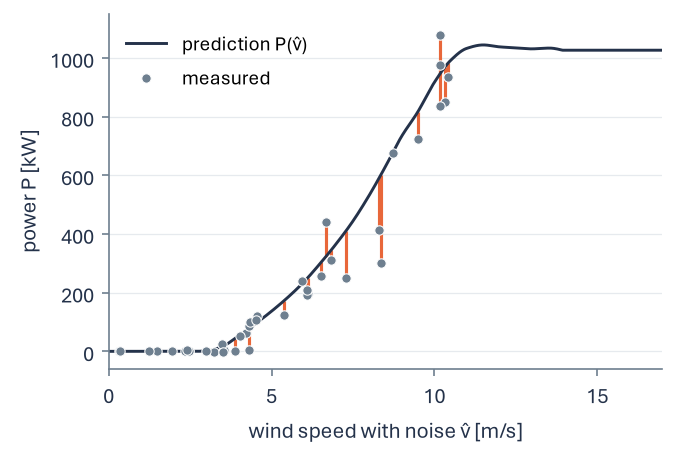

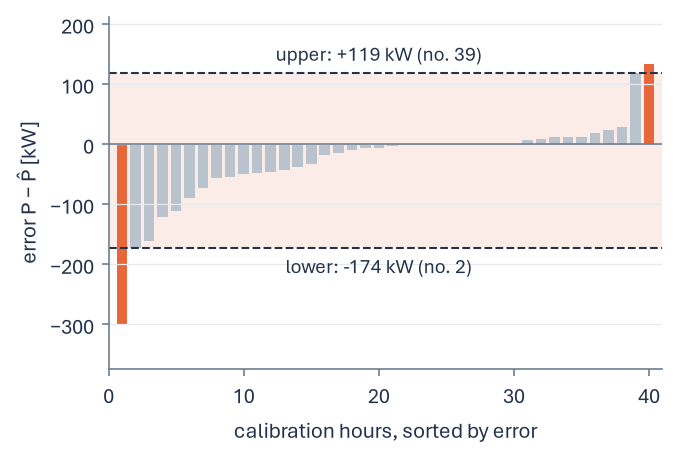

In [3]:
def conformal_interval(errors, alpha=ALPHA):
    """Split conformal interval from signed calibration errors, with a lower and an upper margin.

    Args:
        errors: Signed errors (measured - predicted) of the calibration hours.
        alpha: Allowed miss rate, split equally between both sides (0.1 -> 90 % interval).

    Returns:
        Tuple ``(lower, upper, rank_lower, rank_upper)``: the margins in the unit of the errors and their ranks
        (starting at 1) among the sorted errors. The ranks are kept between 1 and n, which only matters for fewer than 19 errors.
    """
    errors = np.sort(np.asarray(errors))
    n = len(errors)
    rank_lower = int(np.clip(np.floor((n + 1) * alpha / 2), 1, n))
    rank_upper = int(np.clip(np.ceil((n + 1) * (1 - alpha / 2)), 1, n))
    return float(errors[rank_lower - 1]), float(errors[rank_upper - 1]), rank_lower, rank_upper


# 40 random calibration hours at 10 % noise
example = cal.sample(EXAMPLE_HOURS, random_state=EXAMPLE_SEED)
v_hat = example[wind_inputs[EXAMPLE_LEVEL]]
p_hat = power_curve(bins, v_hat)
err = example["p"] - p_hat
lower, upper, rank_lower, rank_upper = conformal_interval(err)

# first plot (slide 16, left): prediction, measurement and the error of each hour (orange line)
v_grid = np.linspace(0, 17, 1000)
fig, ax = plt.subplots(figsize=(4.4, 2.95), layout="constrained")
ax.vlines(v_hat, p_hat, example["p"], color=ORANGE, lw=1.5)
ax.plot(v_grid, power_curve(bins, v_grid), color=INK, lw=1.4, label="prediction P(v̂)")
ax.plot(v_hat, example["p"], "o", ms=4.5, color=DARK_GRAY, mec="white", mew=0.5, zorder=3, label="measured")
style_power_axes(ax, xlabel="wind speed with noise v̂ [m/s]")
ax.legend(loc="upper left", fontsize=9.5)
fig.savefig(f"{FIGURE_DIR}/cp_example_residuals.png", transparent=False, facecolor="white")
plt.show()

# second plot (slide 16, right): sorted errors, the hours between the two margins in gray (inside), the others in orange
ranks = np.arange(1, EXAMPLE_HOURS + 1)
bar_colors = []
for k in ranks:
    if rank_lower <= k <= rank_upper:
        bar_colors.append(GRAY)
    else:
        bar_colors.append(ORANGE)
fig, ax = plt.subplots(figsize=(4.4, 2.95), layout="constrained")
ax.axhspan(lower, upper, color=ORANGE, alpha=0.12, lw=0)   # the whole interval in light orange
ax.bar(ranks, np.sort(err), width=0.78, color=bar_colors)
ax.axhline(0, color=DARK_GRAY, lw=0.8)
ax.axhline(lower, color=INK, ls="--", lw=1)
ax.annotate(f"lower: {lower:+.0f} kW (no. {rank_lower})", (EXAMPLE_HOURS / 2, lower), ha="center", va="top",
            xytext=(0, -3), textcoords="offset points", color=INK, fontsize=9.5)
ax.axhline(upper, color=INK, ls="--", lw=1)
ax.annotate(f"upper: {upper:+.0f} kW (no. {rank_upper})", (EXAMPLE_HOURS / 2, upper), ha="center", va="bottom",
            xytext=(0, 3), textcoords="offset points", color=INK, fontsize=9.5)
ax.set(xlabel="calibration hours, sorted by error", ylabel="error P − P̂ [kW]", xlim=(0, EXAMPLE_HOURS + 1))
ax.set_ylim(min(err) * 1.25, max(upper, max(err)) * 1.6)
ax.grid(axis="x", visible=False)
fig.savefig(f"{FIGURE_DIR}/cp_example_sorted.png", transparent=False, facecolor="white")
plt.show()

## 3. One interval for all hours (classic split conformal)

Now the same with all calibration hours, once for each noise level. The errors include everything that makes the prediction wrong:
the propagated wind noise and the error of the curve itself. The method does not need to know which part comes from where.

We plot the errors directly (residual view): the error $P - \hat P$ against the wind we predict from. Then the interval is just two
horizontal lines. This also explains why the band looked "variable" on our old slide: it has the same height everywhere, but around a
steep curve a fixed height looks thin and around a flat curve it looks wide.

,lower,upper,rank lower,rank upper,width
no noise,-38 kW,+40 kW,79,1516,78 kW
1 %,-41 kW,+44 kW,79,1516,84 kW
5 %,-77 kW,+89 kW,79,1516,166 kW
10 %,-129 kW,+159 kW,79,1516,289 kW


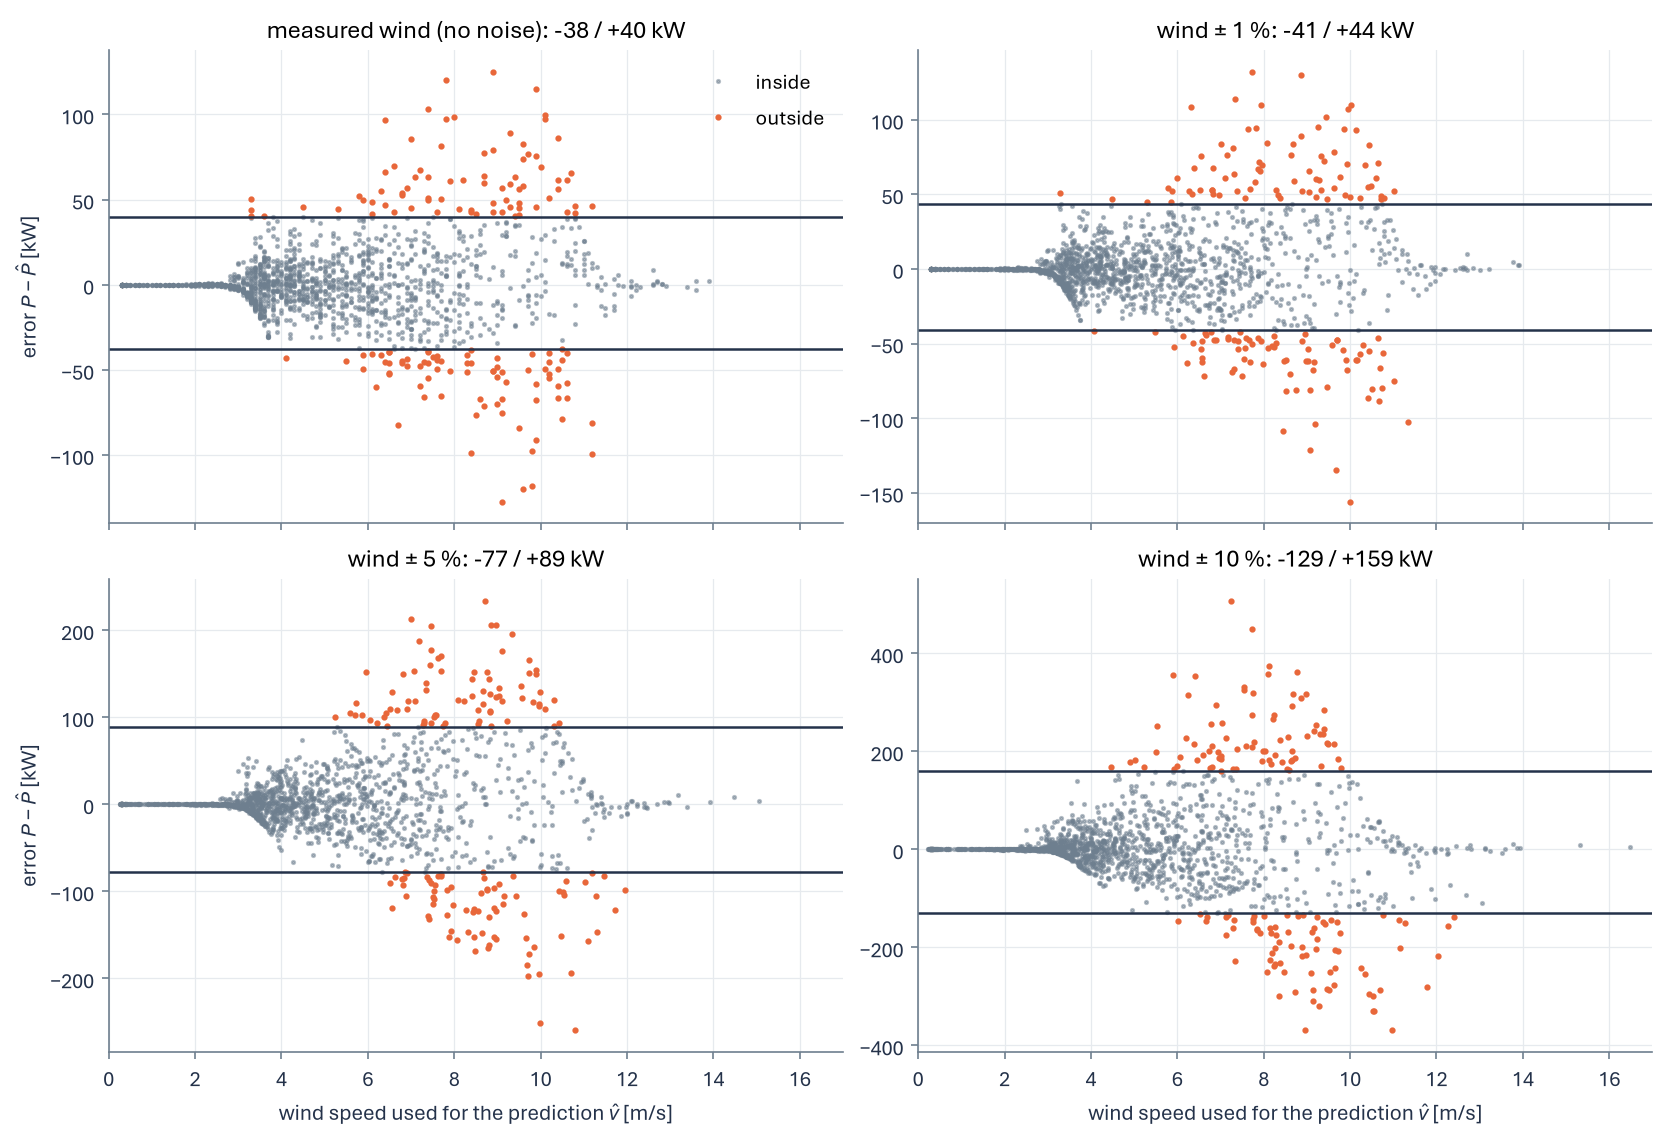

In [4]:
# classic interval for each noise level, from all calibration hours
rows = {}
for label in wind_inputs:
    lower, upper, rank_lower, rank_upper = conformal_interval(error[label])
    rows[label] = {"lower": lower, "upper": upper, "rank lower": rank_lower, "rank upper": rank_upper}
classic = pd.DataFrame(rows).T
classic["width"] = classic["upper"] - classic["lower"]
display(classic.style.format({"lower": "{:+.0f} kW", "upper": "{:+.0f} kW", "width": "{:.0f} kW",
                              "rank lower": "{:.0f}", "rank upper": "{:.0f}"}))

# residual view: errors against the predicted wind, with the two margins
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, layout="constrained")
for ax, label in zip(axes.flat, wind_inputs):
    v_hat = cal[wind_inputs[label]]
    err = error[label]
    lower = classic.loc[label, "lower"]
    upper = classic.loc[label, "upper"]
    inside = err.between(lower, upper)

    ax.plot(v_hat[inside], err[inside], ".", ms=3, color=DARK_GRAY, alpha=0.5, label="inside")
    ax.plot(v_hat[~inside], err[~inside], ".", ms=4, color=ORANGE, label="outside")
    ax.axhline(lower, color=INK, lw=1.2)
    ax.axhline(upper, color=INK, lw=1.2)
    if label == "no noise":
        title = "measured wind (no noise)"
    else:
        title = f"wind ± {label}"
    ax.set(title=f"{title}: {lower:+.0f} / {upper:+.0f} kW", xlim=(0, 17))

axes[1, 0].set_xlabel(r"wind speed used for the prediction $\hat{v}$ [m/s]")
axes[1, 1].set_xlabel(r"wind speed used for the prediction $\hat{v}$ [m/s]")
axes[0, 0].set_ylabel(r"error $P - \hat{P}$ [kW]")
axes[1, 0].set_ylabel(r"error $P - \hat{P}$ [kW]")
axes[0, 0].legend(loc="upper right")
plt.show()

## 4. Does one interval fit all hours?

In the residual view we see the tube from notebook 03 again: the errors are tiny below cut-in, largest on the steep part and one-sided at
rated power. One interval with the same height for all hours therefore covers far more than 90 % of the calm hours and far less on the
steep part. The table shows, per bin of the predicted wind, the share of calibration hours inside the classic interval.
The plot shows the same interval not normalized, as one band around the curve (wind ± 10 %). The band has the same height
everywhere, so the hours outside (orange) are on the steep part of the curve.

In [5]:
# share of calibration hours inside the classic interval, per bin of the predicted wind
rows = {}
for label in wind_inputs:
    inside = error[label].between(classic.loc[label, "lower"], classic.loc[label, "upper"])
    row = {"all hours": inside.mean()}
    row.update(inside.groupby(wind_bin(cal[wind_inputs[label]]), observed=True).mean().to_dict())
    rows[label] = row
classic_by_bin = pd.DataFrame(rows).T

print("hours per bin (wind ± 10 %):", pd.Series(wind_bin(cal["v_noise_10"])).value_counts(sort=False).to_dict())
classic_by_bin.style.format("{:.0%}")

hours per bin (wind ± 10 %): {'0–3 m/s': 306, '3–5 m/s': 546, '5–7 m/s': 345, '7–9 m/s': 223, '9–11 m/s': 121, '≥ 11 m/s': 53}


,all hours,0–3 m/s,3–5 m/s,5–7 m/s,7–9 m/s,9–11 m/s,≥ 11 m/s
no noise,90%,100%,99%,91%,77%,55%,94%
1 %,90%,100%,99%,91%,74%,58%,93%
5 %,90%,100%,100%,92%,65%,67%,84%
10 %,90%,100%,100%,92%,65%,65%,87%


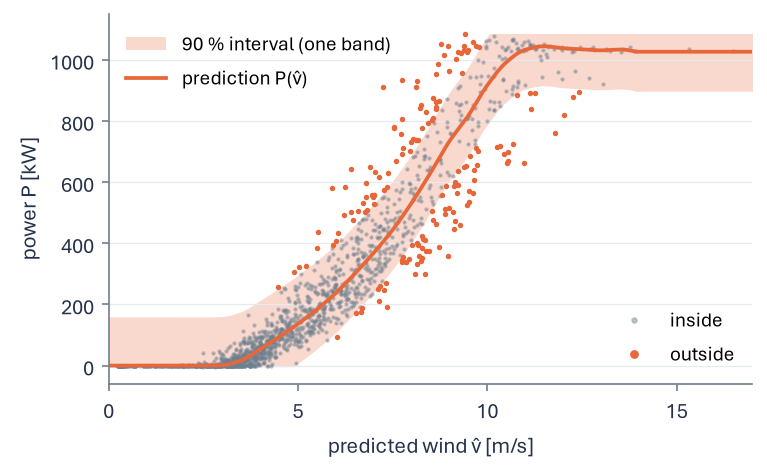

In [6]:
# wind +/- 10 %: the classic interval not normalized, as one band around the curve (slide 17, left)
label = EXAMPLE_LEVEL
v_hat = cal[wind_inputs[label]]
lower = classic.loc[label, "lower"]
upper = classic.loc[label, "upper"]
inside = error[label].between(lower, upper)
p_grid = power_curve(bins, v_grid)

# band cut at the smallest and largest measured power, as for the Mondrian band in section 5
fig, ax = plt.subplots(figsize=(5.0, 3.05), layout="constrained")
ax.fill_between(v_grid, np.clip(p_grid + lower, p_min, p_max), np.clip(p_grid + upper, p_min, p_max), color=ORANGE, alpha=0.25,
                lw=0, label="90 % interval (one band)")
ax.plot(v_hat[inside], cal["p"][inside], ".", ms=2.2, color=DARK_GRAY, alpha=0.4, rasterized=True, label="inside")
ax.plot(v_hat[~inside], cal["p"][~inside], ".", ms=3.2, color=ORANGE, rasterized=True, label="outside")
ax.plot(v_grid, p_grid, color=ORANGE, lw=1.8, label="prediction P(v̂)")
style_power_axes(ax, xlabel="predicted wind v̂ [m/s]")
split_legend(ax, ["inside", "outside"])
fig.savefig(f"{FIGURE_DIR}/classic_band.png", transparent=False, facecolor="white")
plt.show()

## 5. Mondrian: one interval per wind bin

**Mondrian conformal prediction** uses exactly the same method, but separately in each bin of the predicted wind (0-3, 3-5, 5-7, 7-9,
9-11 and above 11 m/s). Every bin gets its own lower and upper margin from its own calibration hours. Then the 90 % should hold in every
bin, not only on average. The bins are based on the wind we predict from, which we know in advance, and every bin has at least about
50 calibration hours. The interval becomes a staircase that follows the tube.

,n,lower,upper
0–3 m/s,306,-1 kW,+7 kW
3–5 m/s,546,-45 kW,+68 kW
5–7 m/s,345,-98 kW,+182 kW
7–9 m/s,223,-217 kW,+309 kW
9–11 m/s,121,-298 kW,+236 kW
≥ 11 m/s,53,-217 kW,+15 kW


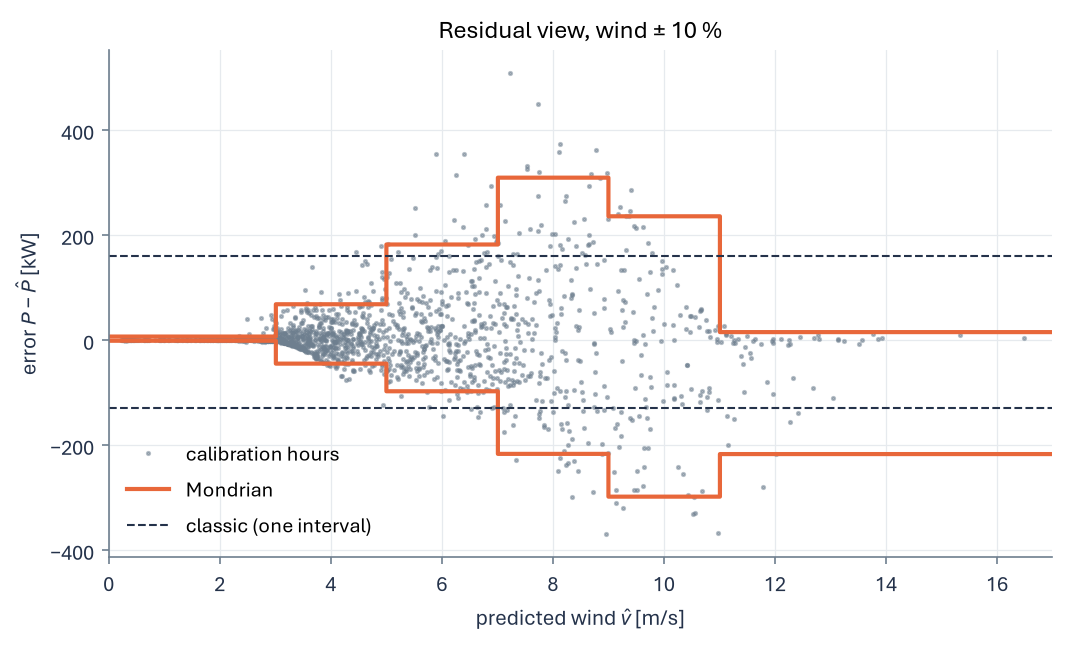

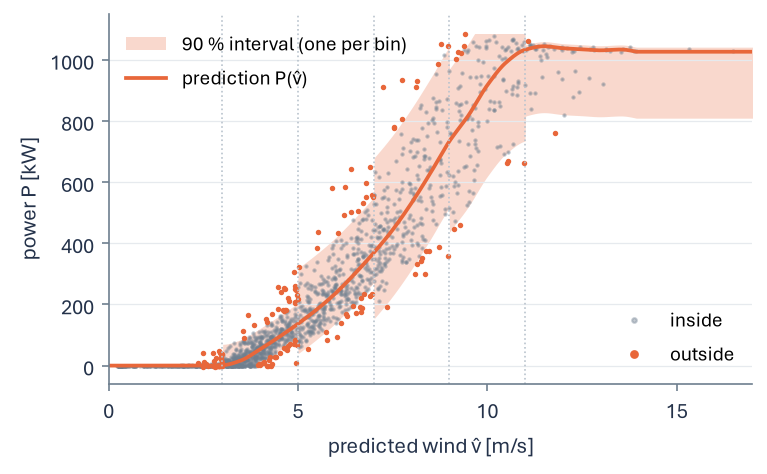

In [7]:
def mondrian_intervals(v_hat, errors):
    """Conformal interval for each bin of the predicted wind.

    Args:
        v_hat: Predicted (noisy) wind speeds of the calibration hours in m/s.
        errors: Signed errors (measured - predicted) of the same hours.

    Returns:
        DataFrame with one row per bin label: number of hours ``n`` and the margins ``lower`` and ``upper``.
    """
    errors = pd.Series(np.asarray(errors))
    table = {}
    for name, group in errors.groupby(wind_bin(v_hat), observed=False):
        lower, upper, rank_lower, rank_upper = conformal_interval(group)
        table[name] = {"n": len(group), "lower": lower, "upper": upper}
    return pd.DataFrame(table).T


def margins_for(v_hat, table):
    """Look up the lower and upper margin of each hour in a table with one row per wind bin.

    Args:
        v_hat: Predicted wind speeds in m/s.
        table: Output of ``mondrian_intervals``.

    Returns:
        Tuple of arrays ``(lower, upper)``, one value per hour.
    """
    labels = wind_bin(v_hat).astype(str)
    return table.loc[labels, "lower"].to_numpy(), table.loc[labels, "upper"].to_numpy()


# Mondrian intervals for every noise level
mondrian = {}
for label in wind_inputs:
    mondrian[label] = mondrian_intervals(cal[wind_inputs[label]], error[label])
display(mondrian[EXAMPLE_LEVEL].style.format({"n": "{:.0f}", "lower": "{:+.0f} kW", "upper": "{:+.0f} kW"})
        .set_caption(f"Mondrian intervals, wind ± {EXAMPLE_LEVEL}"))

# wind +/- 10 %: residual view, classic vs. Mondrian
label = EXAMPLE_LEVEL
v_hat = cal[wind_inputs[label]]
err = error[label]
lower, upper = margins_for(v_grid, mondrian[label])
p_grid = power_curve(bins, v_grid)

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.plot(v_hat, err, ".", ms=3, color=DARK_GRAY, alpha=0.5, label="calibration hours")
ax.step(v_grid, lower, where="post", color=ORANGE, lw=2, label="Mondrian")
ax.step(v_grid, upper, where="post", color=ORANGE, lw=2)
ax.axhline(classic.loc[label, "lower"], color=INK, lw=1, ls="--", label="classic (one interval)")
ax.axhline(classic.loc[label, "upper"], color=INK, lw=1, ls="--")
ax.set(title=f"Residual view, wind ± {label}", xlabel=r"predicted wind $\hat{v}$ [m/s]", ylabel=r"error $P - \hat{P}$ [kW]",
       xlim=(0, 17))
ax.legend(loc="lower left")
plt.show()

# the Mondrian interval around the curve (slide 18, left), cut at the smallest and largest measured power;
# an hour is inside if its error is between the margins of its own bin
lower_hour, upper_hour = margins_for(v_hat, mondrian[label])
inside = (err >= lower_hour) & (err <= upper_hour)
fig, ax = plt.subplots(figsize=(5.0, 3.05), layout="constrained")
ax.fill_between(v_grid, np.clip(p_grid + lower, p_min, p_max), np.clip(p_grid + upper, p_min, p_max), color=ORANGE, alpha=0.25,
                lw=0, label="90 % interval (one per bin)")
ax.plot(v_hat[inside], cal["p"][inside], ".", ms=2.2, color=DARK_GRAY, alpha=0.4, rasterized=True, label="inside")
ax.plot(v_hat[~inside], cal["p"][~inside], ".", ms=3.2, color=ORANGE, rasterized=True, label="outside")
ax.plot(v_grid, p_grid, color=ORANGE, lw=1.8, label="prediction P(v̂)")
# dotted lines at the bin edges
for edge in WIND_BINS[1:-1]:
    ax.axvline(edge, color=GRAY, lw=0.8, ls=":")
style_power_axes(ax, xlabel="predicted wind v̂ [m/s]")
split_legend(ax, ["inside", "outside"])
fig.savefig(f"{FIGURE_DIR}/mondrian_band.png", transparent=False, facecolor="white")
plt.show()

## 6. Does the 90 % hold? Classic vs. Mondrian

If we check the margins on the same hours we computed them from, the check is not fair. With an 80/20 split we have no third data set,
so we split the calibration hours randomly into two halves: we compute the margins from one half and check them on the other half.
We repeat this 500 times. For both methods we save the share of hours inside the interval (overall and per bin) and the mean width
of the interval.

In [8]:
def halving_check(label, method, rng):
    """Coverage and width of conformal intervals computed on one random half of the calibration hours and checked on the other half.

    Args:
        label: Noise level, a key of ``wind_inputs``.
        method: ``"classic"`` (one interval) or ``"mondrian"`` (one interval per wind bin).
        rng: NumPy random generator.

    Returns:
        DataFrame with one row per repetition: coverage overall, mean width and coverage per wind bin.
    """
    v_hat = cal[wind_inputs[label]].to_numpy()
    err = error[label].to_numpy()
    half = len(cal) // 2
    runs = []
    for i in range(CHECK_REPEATS):
        # random halves: margins from the first half, check on the second half
        order = rng.permutation(len(cal))
        first = order[:half]
        second = order[half:]
        if method == "classic":
            lower, upper, rank_lower, rank_upper = conformal_interval(err[first])
            lower = np.full(len(second), lower)
            upper = np.full(len(second), upper)
        else:
            table = mondrian_intervals(v_hat[first], err[first])
            lower, upper = margins_for(v_hat[second], table)
        inside = pd.Series((err[second] >= lower) & (err[second] <= upper))
        run = {"coverage": inside.mean(), "mean width": np.mean(upper - lower)}
        run.update(inside.groupby(wind_bin(v_hat[second]), observed=False).mean().to_dict())
        runs.append(run)
    return pd.DataFrame(runs)


# run the check for every noise level and both methods
rng = np.random.default_rng(CHECK_SEED)
checks = {}
for label in wind_inputs:
    for method in ["classic", "mondrian"]:
        checks[(label, method)] = halving_check(label, method, rng)

# summary over the 500 runs
rows = {}
for (label, method), runs in checks.items():
    coverage_per_bin = runs[WIND_BIN_LABELS].mean()
    rows[(label, method)] = {
        "mean coverage": runs["coverage"].mean(),
        "5 % of the runs below": runs["coverage"].quantile(0.05),
        "5 % of the runs above": runs["coverage"].quantile(0.95),
        "mean width [kW]": runs["mean width"].mean(),
        "lowest bin": coverage_per_bin.min(),
        "highest bin": coverage_per_bin.max(),
    }
summary = pd.DataFrame(rows).T
summary.index.names = ["noise", "method"]
summary.style.format({"mean coverage": "{:.1%}", "5 % of the runs below": "{:.1%}", "5 % of the runs above": "{:.1%}",
                      "mean width [kW]": "{:.0f}", "lowest bin": "{:.1%}", "highest bin": "{:.1%}"})

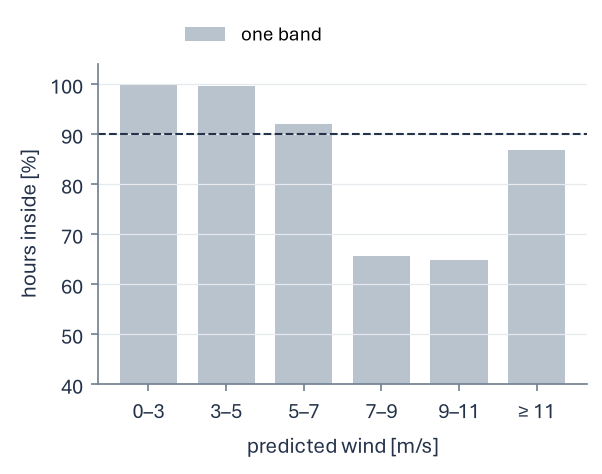

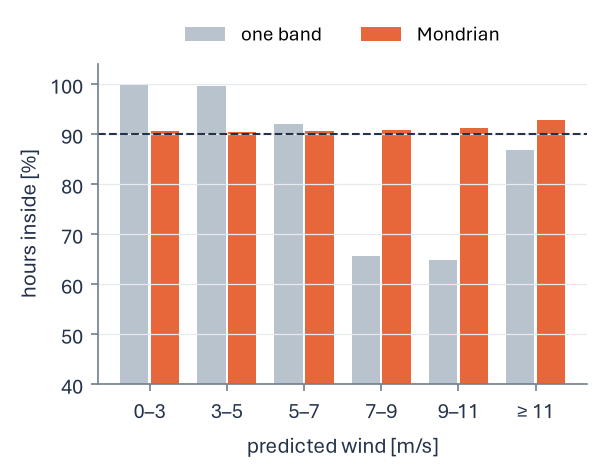

In [9]:
# coverage per wind bin at wind +/- 10 % (mean over the 500 runs)
per_bin = pd.DataFrame({"classic": checks[(EXAMPLE_LEVEL, "classic")][WIND_BIN_LABELS].mean(),
                        "mondrian": checks[(EXAMPLE_LEVEL, "mondrian")][WIND_BIN_LABELS].mean()})

# only the classic interval (slide 17, right)
fig, ax = plt.subplots(figsize=(3.9, 3.05), layout="constrained")
coverage_bars(ax, [per_bin["classic"]], [GRAY], ["one band"])
# same legend row as in the next plot, with the "Mondrian" entry in white: on the slides the chart then keeps its size
# and position when slide 17 changes to slide 18
handles, labels = ax.get_legend_handles_labels()
placeholder = Patch(color="white", label="Mondrian")
legend = ax.legend(handles + [placeholder], labels + ["Mondrian"], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,
                   fontsize=9.5)
legend.get_texts()[1].set_color("white")
fig.savefig(f"{FIGURE_DIR}/coverage_classic.png", transparent=False, facecolor="white")
plt.show()

# classic vs. Mondrian (slide 18, right)
fig, ax = plt.subplots(figsize=(3.9, 3.05), layout="constrained")
coverage_bars(ax, [per_bin["classic"], per_bin["mondrian"]], [GRAY, ORANGE], ["one band", "Mondrian"])
fig.savefig(f"{FIGURE_DIR}/coverage_mondrian.png", transparent=False, facecolor="white")
plt.show()

## 7. Save for the slides

We save the classic margins with the coverage check for each noise level, the Mondrian margins for each noise level and wind bin,
and the coverage per bin.

In [10]:
# classic margins together with the coverage check
classic_check = summary.xs("classic", level="method")
classic.join(classic_check).rename_axis("noise").to_csv("data/conformal_margins.csv")

# Mondrian margins per noise level and wind bin, and the Mondrian coverage check
pd.concat(mondrian, names=["noise", "wind_bin"]).to_csv("data/mondrian_margins.csv")
mondrian_check = summary.xs("mondrian", level="method")
mondrian_check.rename_axis("noise").to_csv("data/mondrian_check.csv")

# coverage per wind bin (mean over the 500 runs) for every noise level and method
rows = []
for (label, method), runs in checks.items():
    for name in WIND_BIN_LABELS:
        rows.append({"noise": label, "method": method, "wind_bin": name, "coverage": runs[name].mean()})
pd.DataFrame(rows).to_csv("data/coverage_by_bin.csv", index=False)
print("saved conformal_margins.csv, mondrian_margins.csv, mondrian_check.csv, coverage_by_bin.csv")

saved conformal_margins.csv, mondrian_margins.csv, mondrian_check.csv, coverage_by_bin.csv


## Takeaways

- **Classic split conformal (one interval)** works on average: 90.1-90.3 % of new hours are inside at every noise level (in 90 % of the
  checks between 87.5 % and 92.7 %). The interval gets wider with the input uncertainty: -38 / +40 kW with the measured wind,
  -41 / +44 kW at 1 %, -77 / +89 kW at 5 % and -129 / +159 kW at 10 % wind noise. The upper margin is larger because the errors are skewed.
- **But one interval does not fit the tube.** It has the same height everywhere (that's why it looked "variable" around the curve). It
  covers 100 % of the calm hours but only 55-67 % of the hours at 7-11 m/s. The 90 % is only an average over very different hours.
- **Mondrian (one interval per wind bin)** solves this: 90-93 % of new hours are inside in every bin, 90.7 % overall, and the interval is
  20-23 % narrower on average (10 %: 225 instead of 291 kW, 5 %: 134 instead of 167 kW). The interval follows the tube: a few kW below
  cut-in, -217 / +309 kW at 7-9 m/s and -217 / +15 kW at rated power (there the turbine can only produce less than predicted).
- Conformal prediction treats the model as a black box: the errors contain the curve error and the propagated noise, and neither method
  needs to know which is which or how they are distributed.

**Limitations:**
- Exchangeability: the training and calibration hours are drawn at random from the same year. For a new year or season the coverage can
  be lower. Notebook 05 tests the method on real weather forecasts with a split in time.
- The bins are chosen by hand (2 m/s wide, based on the predicted wind). The bin above 11 m/s has only 53 calibration hours, so its
  margins are less stable.
- Only normal operation: the calibration hours are cleaned (no stops, no outliers), so the interval does not cover outages.

Next: notebook 05 tests the curve and the intervals on real day-ahead wind forecasts from Open-Meteo.